# Ch 1: Market overview

**Question:** what does the Broward short-term rental market look like in the twelve months to September 2026? How big is it, who runs it, how fast is it growing, when are guests here, and how does it differ across the county?

| Section | Question | Main evidence |
|---|---|---|
| 1.1 | How big is the market? | Sep 2026 snapshot |
| 1.2 | What is listed, and who runs it? | Property type, host and operator tiers |
| 1.3 | How fast is supply growing? | Dec 2025 vs Sep 2026 snapshots |
| 1.4 | Is demand keeping up? | Reviews per month |
| 1.5 | When are guests here? | Seasonal index, forward calendar |
| 1.6 | How do the cities differ? | City table |
| 1.7 | Does being near the beach pay? | Distance bands |
| 1.8 | What does it cost to buy in? | Zillow, DOR sales, mortgage rates |

**Rules followed (from `docs/data_dictionary.md` and `docs/decisions_log.md`):** September 2026 is the main snapshot (December has no prices, March only covers about 55% of listings, June prices are inflated by the World Cup). Performance figures use `analysis_ready == 1`. Nights and revenue are Inside Airbnb's review-based estimates, so medians are for active listings (`active_l12m == 1`, at least one review in the past 12 months).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data/processed")
FIG = Path("figures/ch1")
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 160)
SEP, DEC = pd.Timestamp("2026-09-22"), pd.Timestamp("2025-12-28")

# same palette as the other chapters
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#d4d3cf", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe8",
                     "grid.linewidth": 0.8, "axes.axisbelow": True, "figure.dpi": 110,
                     "savefig.dpi": 200, "savefig.bbox": "tight"})

listings = pd.read_parquet(DATA / "listings_panel.parquet")
reviews = pd.read_parquet(DATA / "reviews.parquet", columns=["listing_id", "date", "city"])
calendar = pd.read_parquet(DATA / "calendar_monthly.parquet")
zillow = pd.read_parquet(DATA / "zillow_zip_monthly.parquet")
rates = pd.read_parquet(DATA / "mortgage_rate_monthly.parquet")
sales = pd.read_parquet(DATA / "dor_sales.parquet")

listings.groupby("snapshot_date").agg(listings=("id", "size"), with_price=("price", "count"),
                                      analysis_ready=("analysis_ready", "sum"))

,listings,with_price,analysis_ready
snapshot_date,,,
2025-12-28,16424,0,0
2026-03-30,9791,9550,9512
2026-06-29,17698,16504,15809
2026-09-22,17630,16387,15698


In [2]:
sep_all = listings[listings.snapshot_date == SEP]
dec_all = listings[listings.snapshot_date == DEC]
sep = sep_all[sep_all.analysis_ready == 1].copy()
active = sep[sep.active_l12m == 1]

PRO = "pro (10+)"
CONDO = ["Entire condo", "Entire rental unit", "Entire serviced apartment"]
HOUSE = ["Entire home", "Entire villa", "Entire townhouse", "Entire vacation home", "Entire cottage"]
sep["product"] = np.select([sep.property_type.isin(CONDO), sep.property_type.isin(HOUSE)],
                           ["apartment/condo", "house"], "other")
sep["near_beach"] = sep.mi_to_beach_approx <= 1

print(f"Sep 2026: {len(sep_all):,} listings, {sep_all.host_id.nunique():,} host accounts")
print(f"analysis_ready sample: {len(sep):,} ({len(sep) / len(sep_all):.0%}); active: {sep.active_l12m.mean():.1%}")

Sep 2026: 17,630 listings, 6,524 host accounts
analysis_ready sample: 15,698 (89%); active: 72.4%


## 1.1 How big is the market?

In [3]:
print("Room type (all Sep listings):")
print(sep_all.room_type.value_counts(normalize=True).round(3).to_string())

entire = sep[sep.room_type == "Entire home/apt"]
size = pd.Series({
    "median bedrooms": sep.bedrooms.median(),
    "median guests": sep.accommodates.median(),
    "median price": sep.price.median(),
    "price p25": sep.price.quantile(0.25),
    "price p75": sep.price.quantile(0.75),
    "median price, entire homes": entire.price.median(),
    "share min nights = 1": (sep.minimum_nights == 1).mean(),
    "share min nights = 2": (sep.minimum_nights == 2).mean(),
    "median nights (active)": active.estimated_occupancy_l365d.median(),
    "median occupancy (active)": active.occupancy_rate_l365d.median(),
    "median revenue (active)": active.estimated_revenue_l365d.median(),
    "p75 revenue (active)": active.estimated_revenue_l365d.quantile(0.75),
    "total revenue, $M": sep.estimated_revenue_l365d.sum() / 1e6,
})
size.round(3)

Room type (all Sep listings):
room_type
Entire home/apt   0.84
Private room      0.14
Hotel room        0.01
Shared room       0.01


median bedrooms                   1.00
median guests                     4.00
median price                    232.20
price p25                       152.69
price p75                       358.50
median price, entire homes      249.50
share min nights = 1              0.48
share min nights = 2              0.30
median nights (active)           72.00
median occupancy (active)         0.20
median revenue (active)      16,104.00
p75 revenue (active)         34,210.00
total revenue, $M               289.43
dtype: float64

In [4]:
# How concentrated is revenue?
rev = sep.estimated_revenue_l365d.sort_values(ascending=False)
top10 = rev.head(len(rev) // 10).sum() / rev.sum()
print(f"Top 10% of listings earn {top10:.0%} of estimated revenue")

# Cross-check against Airbnb's tax remittance: $22.4M for Broward, Jun 2024 to Jun 2025 (Airbnb newsroom).
# Taxable bookings it implies depend on which taxes it covers.
tax = 22.4
print(f"Implied bookings: ${tax / 0.06:,.0f}M if 6% TDT only, ${tax / 0.13:,.0f}M if 13% (state + surtax + TDT)")
print(f"Share of 2025 county TDT ($124M): {tax / 0.13 * 0.06 / 124:.0%} to {tax / 124:.0%}")

Top 10% of listings earn 45% of estimated revenue
Implied bookings: $373M if 6% TDT only, $172M if 13% (state + surtax + TDT)
Share of 2025 county TDT ($124M): 8% to 18%


## 1.2 What is listed, and who runs it?

Two products make up most of the market: apartment and condo units (Airbnb types condo, rental unit, serviced apartment) and houses (home, villa, townhouse, vacation home, cottage). Professional = a host account with 10+ listings across all markets (`host_tier`, the team standard in `docs/data_dictionary.md`). The operator table below groups linked accounts (such as Stay Sol's ten) to show who the biggest operators are.

In [5]:
prod = sep.groupby("product").agg(
    listings=("id", "size"),
    near_beach=("near_beach", "mean"),
    median_bedrooms=("bedrooms", "median"),
    studio_or_1br=("bedrooms", lambda x: (x <= 1).mean()),
    pro_share=("host_tier", lambda x: (x == PRO).mean()),
)
prod["median_rev_active"] = active.assign(product=sep["product"]).groupby("product").estimated_revenue_l365d.median()
prod

,listings,near_beach,median_bedrooms,studio_or_1br,pro_share,median_rev_active
product,,,,,,
apartment/condo,7965,0.70,1.00,0.61,0.67,"11,742.00"
house,4642,0.24,3.00,0.09,0.33,"32,310.00"
other,3091,0.30,1.00,0.86,0.36,"7,614.00"


In [6]:
# apartments/condos near the beach vs further inland
apt = sep[sep["product"] == "apartment/condo"]
apt_act = apt[apt.active_l12m == 1]
pd.DataFrame({
    "listings": apt.groupby("near_beach").size(),
    "pro_share": apt.groupby("near_beach").host_tier.apply(lambda x: (x == PRO).mean()),
    "median_rev_active": apt_act.groupby("near_beach").estimated_revenue_l365d.median(),
})

,listings,pro_share,median_rev_active
near_beach,,,
False,2414,0.57,"14,375.00"
True,5551,0.72,"10,431.00"


In [7]:
# Host tier is based on the account's total listings on Airbnb
accounts = sep_all.drop_duplicates("host_id")
tiers = pd.DataFrame({"share_of_listings": sep_all.host_tier.value_counts(normalize=True),
                      "share_of_accounts": accounts.host_tier.value_counts(normalize=True)})
print(tiers.round(3))

ops = sep_all.groupby("operator_key").agg(listings=("id", "size"), accounts=("host_id", "nunique"),
                                          main_city=("city", lambda x: x.value_counts().index[0]),
                                          share_main_city=("city", lambda x: x.value_counts(normalize=True).iloc[0]))
ops.sort_values("listings", ascending=False).head(5)

             share_of_listings  share_of_accounts
host_tier                                        
single                    0.20               0.53
small (2-9)               0.31               0.36
pro (10+)                 0.49               0.11


,listings,accounts,main_city,share_main_city
operator_key,,,,
stay sol,926,10,Hollywood,0.54
beachwalk,671,6,Hallandale Beach,0.97
host_442029804,142,1,Pompano Beach,0.73
host_1833853,136,1,Hallandale Beach,0.52
roompicks,125,8,Fort Lauderdale,0.57


In [8]:
# Raw comparison of single hosts and professionals (Ch 2 and 4 do the controlled version)
act_tier = active.groupby("host_tier", observed=True).agg(
    listings=("id", "size"), median_rev=("estimated_revenue_l365d", "median"),
    median_nights=("estimated_occupancy_l365d", "median"),
    house_share=("property_type", lambda x: x.isin(HOUSE).mean()),
    near_beach=("mi_to_beach_approx", lambda x: (x <= 1).mean()))
act_tier

,listings,median_rev,median_nights,house_share,near_beach
host_tier,,,,,
single,2094,"19,764.50",84.00,0.52,0.29
small (2-9),3772,"17,597.50",80.00,0.41,0.35
pro (10+),5501,"13,493.00",54.00,0.25,0.58


## 1.3 How fast is supply growing?

All listings, December 2025 to September 2026 (March is skipped because the scrape was incomplete).

In [9]:
dec_ids, sep_ids = set(dec_all.id), set(sep_all.id)
exits = dec_all[~dec_all.id.isin(sep_ids)]
entries = sep_all[~sep_all.id.isin(dec_ids)]
print(f"Dec {len(dec_all):,} -> Sep {len(sep_all):,} ({len(sep_all) / len(dec_all) - 1:.1%})")
print(f"Left: {len(exits):,} ({len(exits) / len(dec_all):.0%} of Dec), new: {len(entries):,}")

churn = pd.DataFrame({
    "exit_rate": dec_all.assign(gone=~dec_all.id.isin(sep_ids)).groupby("host_tier", observed=True).gone.mean(),
    "new_listings": entries.host_tier.value_counts(),
})
churn

Dec 16,424 -> Sep 17,630 (7.3%)
Left: 4,279 (26% of Dec), new: 5,485


,exit_rate,new_listings
host_tier,,
single,0.25,1029
small (2-9),0.26,1484
pro (10+),0.27,2972


In [10]:
bw = entries[entries.operator_key == "beachwalk"]
net = len(sep_all) - len(dec_all)
print(f"Beachwalk new listings: {len(bw)} ({len(bw) / net:.0%} of net growth), "
      f"{len(bw[['latitude', 'longitude']].round(3).drop_duplicates())} distinct points at ~100 m")
hb = (sep_all.city == "Hallandale Beach").sum() - (dec_all.city == "Hallandale Beach").sum()
print(f"Hallandale Beach net change: {hb:+}")

city_growth = pd.DataFrame({"dec": dec_all.city.value_counts(), "sep": sep_all.city.value_counts()})
city_growth["growth"] = city_growth.sep / city_growth.dec - 1
city_growth.sort_values("sep", ascending=False).head(9)

Beachwalk new listings: 607 (50% of net growth), 12 distinct points at ~100 m
Hallandale Beach net change: +251


,dec,sep,growth
city,,,
Fort Lauderdale,4287,4492,0.05
Hollywood,3971,4199,0.06
Pompano Beach,1923,2173,0.13
Hallandale Beach,1745,1996,0.14
Deerfield Beach,752,758,0.01
Dania Beach,500,528,0.06
Wilton Manors,489,519,0.06
Lauderdale By The Sea,440,489,0.11
Oakland Park,445,465,0.04


In [11]:
# Densest square kilometer: 100 m grid, then a sliding 10 x 10 window
from scipy.ndimage import uniform_filter

x = (sep.longitude * 111.32 * np.cos(np.radians(26.1)) * 10).astype(int)
y = (sep.latitude * 110.57 * 10).astype(int)
grid = pd.crosstab(y, x).reindex(index=range(y.min(), y.max() + 1), columns=range(x.min(), x.max() + 1),
                                 fill_value=0).to_numpy()
window = uniform_filter(grid.astype(float), size=10, mode="constant") * 100
i, j = np.unravel_index(window.argmax(), window.shape)
y0, x0 = y.min() + i - 5, x.min() + j - 5
cell = sep[(y >= y0) & (y < y0 + 10) & (x >= x0) & (x < x0 + 10)]
print(f"Densest km2: {len(cell):,} listings ({len(cell) / len(sep):.0%} of sample), "
      f"{(cell.host_tier == PRO).mean():.0%} professional, cities: {cell.city.value_counts().to_dict()}")

Densest km2: 2,746 listings (17% of sample), 78% professional, cities: {'Hallandale Beach': 1394, 'Hollywood': 1352}


## 1.4 Is demand keeping up?

Airbnb does not publish bookings, so reviews stand in for stays. `reviews.parquet` takes each listing's reviews from the latest snapshot it appears in, so listings that left before December 2025 are missing and early years are understated. September 2026 is partial (review lag), so the series stops in August. I compare like-for-like months year over year rather than reading the long-run trend.

In [12]:
reviews["month"] = reviews.date.dt.to_period("M")
monthly = reviews.groupby("month").agg(reviews=("listing_id", "size"), listings=("listing_id", "nunique"))
monthly = monthly.loc["2019-01":"2026-08"]
monthly["per_listing"] = monthly.reviews / monthly.listings
print(f"Peak month: {monthly.reviews.idxmax()} ({monthly.reviews.max():,} reviews)")
print(f"Total reviews in file: {len(reviews):,}")

def yoy(first, last):
    """Change vs the same months a year earlier."""
    now = monthly.loc[first:last]
    before = monthly.loc[str(pd.Period(first) - 12):str(pd.Period(last) - 12)]
    return pd.Series({"reviews_pct": (now.reviews.sum() / before.reviews.sum() - 1) * 100,
                      "reviewed_listings_pct": (now.listings.sum() / before.listings.sum() - 1) * 100,
                      "per_listing_now": now.reviews.sum() / now.listings.sum(),
                      "per_listing_before": before.reviews.sum() / before.listings.sum()})

pd.DataFrame({"Oct 25-Aug 26": yoy("2025-10", "2026-08"), "Oct 24-Aug 25": yoy("2024-10", "2025-08"),
              "Oct 25-May 26 (no World Cup)": yoy("2025-10", "2026-05")})

Peak month: 2026-03 (25,496 reviews)
Total reviews in file: 835,772


,Oct 25-Aug 26,Oct 24-Aug 25,Oct 25-May 26 (no World Cup)
reviews_pct,22.39,31.91,25.16
reviewed_listings_pct,21.36,33.48,22.99
per_listing_now,2.60,2.58,2.66
per_listing_before,2.58,2.61,2.61


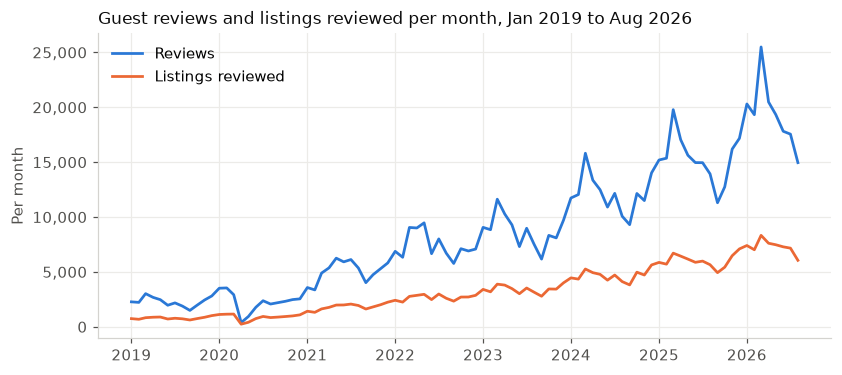

In [13]:
fig, ax = plt.subplots(figsize=(8.6, 3.6))
t = monthly.index.to_timestamp()
ax.plot(t, monthly.reviews, color=BLUE, lw=1.8, label="Reviews")
ax.plot(t, monthly.listings, color=ORANGE, lw=1.8, label="Listings reviewed")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_ylabel("Per month")
ax.legend(loc="upper left", frameon=False)
ax.set_title("Guest reviews and listings reviewed per month, Jan 2019 to Aug 2026", loc="left", fontsize=11, color=INK)
fig.savefig(FIG / "1_4_reviews_per_month.png")
plt.show()

In [14]:
# Same comparison by city, Oct 2025-Aug 2026 vs a year earlier
cities = ["Fort Lauderdale", "Hollywood", "Pompano Beach", "Hallandale Beach", "Deerfield Beach",
          "Wilton Manors", "Lauderdale By The Sea", "Dania Beach", "Oakland Park"]
now = reviews[(reviews.month >= pd.Period("2025-10")) & (reviews.month <= pd.Period("2026-08"))]
before = reviews[(reviews.month >= pd.Period("2024-10")) & (reviews.month <= pd.Period("2025-08"))]
city_rev = (now.city.value_counts() / before.city.value_counts() - 1).rename("review_growth")
pd.concat([city_rev, city_growth.growth.rename("supply_growth")], axis=1).loc[cities].round(3)

,review_growth,supply_growth
city,,
Fort Lauderdale,0.17,0.05
Hollywood,0.31,0.06
Pompano Beach,0.16,0.13
Hallandale Beach,0.14,0.14
Deerfield Beach,0.23,0.01
Wilton Manors,0.16,0.06
Lauderdale By The Sea,0.31,0.11
Dania Beach,0.28,0.06
Oakland Park,0.23,0.04


## 1.5 When are guests here?

Each year's months are scaled to that year's monthly average (= 100), then 2023 to 2025 are averaged, so growth does not distort the pattern. Same method as Ch 6.

In [15]:
def seasonal_index(r):
    r = r[(r.date >= "2023-01-01") & (r.date < "2026-01-01")]
    m = r.groupby([r.date.dt.year.rename("year"), r.date.dt.month.rename("month")]).size().rename("n").reset_index()
    m["index"] = m.n / m.groupby("year").n.transform("mean") * 100
    return m.pivot(index="month", columns="year", values="index").mean(axis=1)

season = seasonal_index(reviews)
print(f"Dec-May: {season.loc[[12, 1, 2, 3, 4, 5]].mean():.0f}, Jun-Nov: {season.loc[6:11].mean():.0f}")
season.round(0)

Dec-May: 110, Jun-Nov: 90


month
1    100.00
2    100.00
3    131.00
4    113.00
5    104.00
6     90.00
7    100.00
8     86.00
9     74.00
10    93.00
11    98.00
12   113.00
dtype: float64

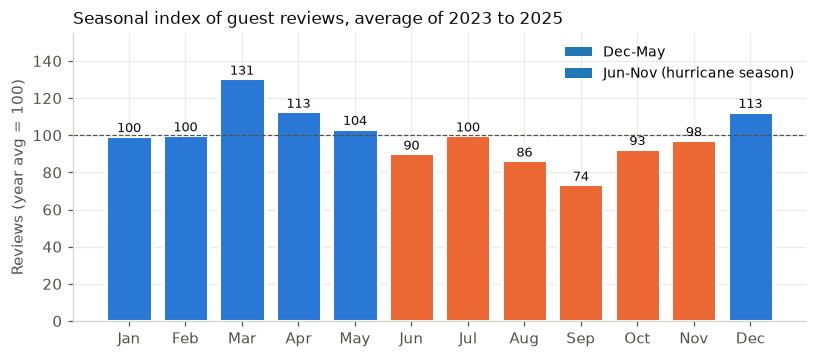

In [16]:
fig, ax = plt.subplots(figsize=(8.6, 3.4))
colors = [ORANGE if 6 <= m <= 11 else BLUE for m in season.index]
ax.bar(season.index, season, color=colors, edgecolor="white", linewidth=2)
ax.bar([], [], color=BLUE, label="Dec-May")
ax.bar([], [], color=ORANGE, label="Jun-Nov (hurricane season)")
ax.legend(loc="upper right", frameon=False, fontsize=9)
ax.axhline(100, color=INK2, lw=0.8, ls="--")
for m, v in season.items():
    ax.text(m, v + 2, f"{v:.0f}", ha="center", fontsize=8.5, color=INK)
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylim(0, 155)
ax.set_ylabel("Reviews (year avg = 100)")
ax.set_title("Seasonal index of guest reviews, average of 2023 to 2025", loc="left", fontsize=11, color=INK)
fig.savefig(FIG / "1_5_seasonal_index.png")
plt.show()

In [17]:
# Do beach towns swing more?
by_city = pd.DataFrame({c: seasonal_index(reviews[reviews.city == c]) for c in cities}).T
by_city[[3, 9]].rename(columns={3: "March", 9: "September"}).sort_values("September").round(0)

month,March,September
Lauderdale By The Sea,131.00,63.00
Dania Beach,144.00,68.00
Deerfield Beach,128.00,69.00
Hallandale Beach,136.00,69.00
Pompano Beach,123.00,72.00
Wilton Manors,130.00,74.00
Oakland Park,132.00,74.00
Hollywood,135.00,75.00
Fort Lauderdale,126.00,76.00


In [18]:
# Forward calendar from the Sep scrape: share of Feb 2027 nights already unavailable (booked or blocked)
cal = calendar[(calendar.snapshot_date == SEP) & (calendar.month == "2027-02")]
cal = cal.merge(sep[["id", "near_beach"]], left_on="listing_id", right_on="id")
feb = cal.groupby("near_beach")[["unavailable_days", "days"]].sum()
(feb.unavailable_days / feb.days).rename({True: "within 1 mi of beach", False: "further inland"}).round(3)

near_beach
further inland         0.32
within 1 mi of beach   0.38
dtype: float64

## 1.6 How do the cities differ?

The nine largest cities, plus two groups for the rest. Growth uses all listings; everything else uses the `analysis_ready` sample.

In [19]:
OTHER_BEACH = ["Hillsboro Beach", "Lighthouse Point", "Sea Ranch Lakes"]

def city_group(c):
    if c in cities:
        return c
    return "Other beach towns" if c in OTHER_BEACH else "All other (inland) cities"

for df in (sep, dec_all, sep_all):
    df["city_group"] = df.city.map(city_group)
active = sep[sep.active_l12m == 1]

def summarize(s, a, d, f):
    return pd.Series({
        "listings": len(s),
        "growth": len(f) / len(d) - 1,
        "pro_share": (s.host_tier == PRO).mean(),
        "active_share": s.active_l12m.mean(),
        "median_price": s.price.median(),
        "median_nights": a.estimated_occupancy_l365d.median(),
        "median_revenue": a.estimated_revenue_l365d.median(),
        "near_beach": s.near_beach.mean(),
        "house_share": s.property_type.isin(HOUSE).mean(),
    })

order = cities + ["Other beach towns", "All other (inland) cities"]
table1 = pd.DataFrame({g: summarize(sep[sep.city_group == g], active[active.city_group == g],
                                    dec_all[dec_all.city_group == g], sep_all[sep_all.city_group == g])
                       for g in order}).T
table1.loc["Broward County"] = summarize(sep, active, dec_all, sep_all)
table1.to_csv(FIG / "table1_cities.csv")
table1

,listings,growth,pro_share,active_share,median_price,median_nights,median_revenue,near_beach,house_share
Fort Lauderdale,"3,996.00",0.05,0.53,0.79,240.50,90.00,"21,840.00",0.38,0.36
Hollywood,"3,783.00",0.06,0.53,0.77,255.00,60.00,"14,688.00",0.66,0.22
Pompano Beach,"1,932.00",0.13,0.64,0.57,234.00,60.00,"13,599.00",0.57,0.28
Hallandale Beach,"1,770.00",0.14,0.79,0.54,200.00,24.00,"4,800.00",0.84,0.07
Deerfield Beach,686.00,0.01,0.34,0.81,214.00,70.00,"14,994.00",0.58,0.41
Wilton Manors,475.00,0.06,0.36,0.85,255.67,96.00,"23,864.50",0.00,0.51
Lauderdale By The Sea,463.00,0.11,0.54,0.83,237.00,66.00,"16,515.00",1.00,0.27
Dania Beach,458.00,0.06,0.32,0.79,198.12,102.00,"22,032.00",0.00,0.45
Oakland Park,428.00,0.04,0.25,0.84,255.00,90.00,"21,420.00",0.00,0.60
Other beach towns,115.00,0.08,0.49,0.80,332.77,72.00,"23,411.00",0.91,0.67


In [20]:
# Hallandale Beach without Beachwalk and Stay Sol
hal = active[active.city == "Hallandale Beach"]
big2 = sep[sep.city == "Hallandale Beach"].operator_key.isin(["beachwalk", "stay sol"]).mean()
print(f"Beachwalk + Stay Sol share of Hallandale sample: {big2:.0%}")
print(f"Median nights, active Hallandale listings excl. Beachwalk: "
      f"{hal[hal.operator_key != 'beachwalk'].estimated_occupancy_l365d.median():.0f}")

Beachwalk + Stay Sol share of Hallandale sample: 60%
Median nights, active Hallandale listings excl. Beachwalk: 36


## 1.7 Does being near the beach pay?

`mi_to_beach_approx` is the distance from the published location (shifted up to ~150 m by Inside Airbnb) to the shoreline.

In [21]:
bands = [0, 0.25, 1, 3, 6, np.inf]
labels = ["< 0.25 mi", "0.25-1 mi", "1-3 mi", "3-6 mi", "6+ mi"]
sep["beach_band"] = pd.cut(sep.mi_to_beach_approx, bands, labels=labels, right=False)
active = sep[sep.active_l12m == 1]
beach = pd.DataFrame({
    "listings": sep.groupby("beach_band", observed=True).size(),
    "pro_share": sep.groupby("beach_band", observed=True).host_tier.apply(lambda x: (x == PRO).mean()),
    "median_nights": active.groupby("beach_band", observed=True).estimated_occupancy_l365d.median(),
    "median_revenue": active.groupby("beach_band", observed=True).estimated_revenue_l365d.median(),
    "median_bedrooms": sep.groupby("beach_band", observed=True).bedrooms.median(),
})
beach["share"] = beach.listings / beach.listings.sum()
beach

,listings,pro_share,median_nights,median_revenue,median_bedrooms,share
beach_band,,,,,,
< 0.25 mi,4463,0.65,54.00,"12,243.00",1.00,0.28
0.25-1 mi,3114,0.69,48.00,"13,896.00",2.00,0.20
1-3 mi,4379,0.42,90.00,"20,747.50",2.00,0.28
3-6 mi,2252,0.40,84.00,"17,070.00",2.00,0.14
6+ mi,1490,0.18,78.00,"15,840.00",1.00,0.09


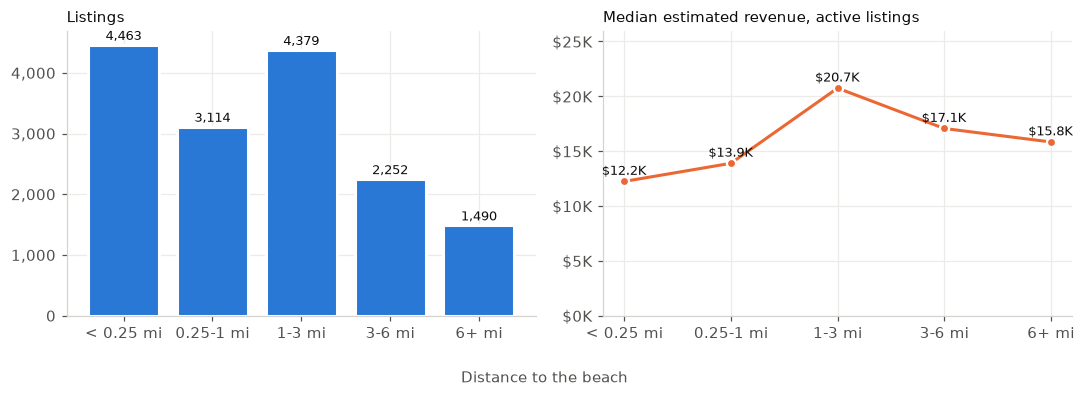

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
xs = np.arange(len(beach))
ax1.bar(xs, beach.listings, color=BLUE, edgecolor="white", linewidth=2)
for i, v in enumerate(beach.listings):
    ax1.text(i, v + 80, f"{v:,}", ha="center", fontsize=8.5, color=INK)
ax1.set_xticks(xs, beach.index)
ax1.set_title("Listings", loc="left", fontsize=10, color=INK)
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")

ax2.plot(xs, beach.median_revenue, color=ORANGE, marker="o", lw=2, mec="white", mew=1.5)
for i, v in enumerate(beach.median_revenue):
    ax2.text(i, v + 600, f"${v / 1000:,.1f}K", ha="center", fontsize=8.5, color=INK)
ax2.set_xticks(xs, beach.index)
ax2.set_ylim(0, beach.median_revenue.max() * 1.25)
ax2.yaxis.set_major_formatter(lambda v, _: f"${v / 1000:,.0f}K")
ax2.set_title("Median estimated revenue, active listings", loc="left", fontsize=10, color=INK)
fig.supxlabel("Distance to the beach", fontsize=10, color=INK2)
fig.tight_layout()
fig.savefig(FIG / "1_7_beach_distance.png")
plt.show()

## 1.8 What does it cost to buy in?

Most listings are condo units, so the condo market matters for anyone entering. Zillow values are the median across Broward ZIPs; sales are from the Florida DOR file (Jan 2025 to Jun 2026). The Ch 6 break-even model builds on these.

In [23]:
z = zillow.groupby("month")[["zhvi_condo", "zhvi_all", "zori_rent"]].median()
peak = z.zhvi_condo.idxmax()
zillow_summary = pd.Series({
    "condo value Sep 2026": z.loc["2026-09-01", "zhvi_condo"],
    "condo 1y change": z.loc["2026-09-01", "zhvi_condo"] / z.loc["2025-09-01", "zhvi_condo"] - 1,
    "condo change from peak": z.loc["2026-09-01", "zhvi_condo"] / z.zhvi_condo.max() - 1,
    "all homes 1y change": z.loc["2026-09-01", "zhvi_all"] / z.loc["2025-09-01", "zhvi_all"] - 1,
    "rent 1y change": z.loc["2026-09-01", "zori_rent"] / z.loc["2025-09-01", "zori_rent"] - 1,
})
print("Condo peak month:", peak.strftime("%b %Y"))
zillow_summary.round(3)

Condo peak month: Dec 2023


condo value Sep 2026     219,619.04
condo 1y change               -0.05
condo change from peak        -0.18
all homes 1y change            0.00
rent 1y change                 0.01
dtype: float64

In [24]:
condos = sales[sales.property_type == "condo"]
h1 = condos[condos.sale_mo <= 6].groupby("sale_yr").agg(sales=("sale_prc", "size"),
                                                        median_price=("sale_prc", "median"),
                                                        median_ppsf=("price_per_sqft", "median"),
                                                        median_sqft=("tot_lvg_area", "median"),
                                                        median_year_built=("act_yr_blt", "median"))
h1.loc["change"] = h1.loc[2026] / h1.loc[2025] - 1
h1

,sales,median_price,median_ppsf,median_sqft,median_year_built
sale_yr,,,,,
2025,"4,757.00","245,000.00",234.72,"1,075.00","1,978.00"
2026,"4,029.00","239,000.00",227.59,"1,100.00","1,979.00"
change,-0.15,-0.02,-0.03,0.02,0.00


In [25]:
r = rates.set_index("month").mortgage_30yr_rate
print(f"30-year rate: Sep 2025 {r['2025-09-01']:.2f}%, Sep 2026 {r['2026-09-01']:.2f}%, Oct 2026 {r['2026-10-01']:.2f}%")

# Monthly principal and interest on the median H1 2026 condo, 20% down
price = h1.loc[2026, "median_price"]
for when in ["2021-09-01", "2026-09-01"]:
    m = r[when] / 100 / 12
    pmt = price * 0.8 * m / (1 - (1 + m) ** -360)
    print(f"  at the {pd.Timestamp(when):%b %Y} rate: ${pmt:,.0f} a month on ${price:,.0f}")

30-year rate: Sep 2025 6.35%, Sep 2026 6.86%, Oct 2026 7.36%
  at the Sep 2021 rate: $796 a month on $239,000
  at the Sep 2026 rate: $1,254 a month on $239,000


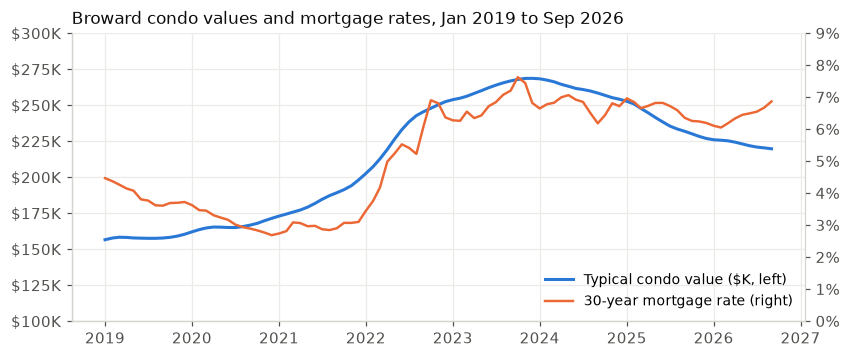

In [26]:
fig, ax = plt.subplots(figsize=(8.6, 3.4))
zz = z.loc["2019-01-01":]
ax.plot(zz.index, zz.zhvi_condo / 1000, color=BLUE, lw=2, label="Typical condo value ($K, left)")
ax.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}K")
ax.set_ylim(100, 300)
ax2 = ax.twinx()
rr = r.loc["2019-01-01":"2026-09-01"]
ax2.plot(rr.index, rr, color=ORANGE, lw=1.6, label="30-year mortgage rate (right)")
ax2.set_ylim(0, 9)
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax2.spines["right"].set_visible(True)
ax2.grid(False)
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], loc="lower right", frameon=False, fontsize=9)
ax.set_title("Broward condo values and mortgage rates, Jan 2019 to Sep 2026", loc="left", fontsize=11, color=INK)
fig.savefig(FIG / "1_8_condo_values_rates.png")
plt.show()

## Findings for the report

September 2026 snapshot, `analysis_ready` sample (15,698 listings); nights and revenue are Inside Airbnb estimates for active listings. Every figure below is printed by a cell above.

1. **Large market.** 17,630 listings from 6,524 host accounts; 84% entire homes. Median price $232 ($250 for entire homes, IQR $153 to $359). The median active listing booked about 72 nights (20% of the year) and earned about $16,100; the top 10% of listings take 45% of revenue. Total estimated revenue is about $289M, inside the $172M to $373M range implied by Airbnb's $22.4M tax remittance.
2. **Two products.** About 8,000 apartment/condo units (70% within a mile of the beach, 61% studios or 1BR, 67% professional) and about 4,600 houses (median 3BR, 33% professional). Active houses earn a median $32,300 against $11,700 for apartments/condos.
3. **Professionalized.** Hosts with 10+ listings run 49% of listings but are 11% of accounts; single-listing hosts are 53% of accounts and 20% of listings. Stay Sol (926 listings, 10 accounts) and Beachwalk (671, 6 accounts) dominate Hallandale Beach and South Hollywood. Raw medians favor single hosts ($19,800 vs $13,500), but single hosts run far more houses (52% vs 25%) and far fewer beach units (29% vs 58%).
4. **Growth with churn.** Supply rose 7.3% (16,424 to 17,630) from December to September, but 26% of December listings left and 5,485 arrived. Exit rates are 25% to 27% for every host tier. Beachwalk's 607 new units (12 map points) are half of net growth. The densest square kilometer (Hallandale/Hollywood beach strip) holds 2,746 listings, 17% of the sample, 78% professional.
5. **Demand shared, not filled.** Reviews Oct 2025 to Aug 2026 rose 22% year over year, but reviewed listings rose 21%, so reviews per listing stayed at about 2.6 a month. Same pattern without the World Cup months and the year before. Hallandale Beach and Pompano Beach (fastest supply growth) had the weakest review growth (14% and 16%).
6. **Seasonal.** March peaks at 131, September bottoms at 74; Dec-May averages 110, Jun-Nov 90. Lauderdale-By-The-Sea swings from 131 to 63; Fort Lauderdale and Hollywood are the most stable (75 to 76 in September). In the forward calendar, 38% of Feb 2027 nights within a mile of the beach were already unavailable vs 32% inland.
7. **Three submarkets.** Saturated beach condo markets (Hallandale Beach: 79% professional, 54% active, 24 median nights), established mixed markets (Fort Lauderdale: 90 nights, $21,800), and inland neighborhoods (Wilton Manors, Oakland Park, Dania Beach: 25% to 36% professional, 90 to 102 nights, $21,400 to $23,900).
8. **Beachfront crowded.** 48% of listings are within a mile of the beach, about two-thirds professional, with the fewest nights (48 to 54). Revenue peaks 1 to 3 miles inland ($20,700, 90 nights).
9. **Soft condo market, expensive money.** Zillow's typical Broward condo value is down 5% in a year and 18% from its December 2023 peak. Condo sales in H1 2026 fell 15% in number and 2% in median price ($239K). The 30-year rate was 6.86% in September and 7.36% in October 2026; at 6.86%, principal and interest on the median condo with 20% down is about $1,250 a month.